____
__Universidad Tecnológica Nacional, Buenos Aires__<br/>
__Ingeniería Industrial__<br/>
__Cátedra de Ciencia de Datos - Curso I5521 - Turno jueves noche__<br/>
__Trabajo Práctico Final: Bank Subscription - Modelos de Machine Learning__<br/>
__Elaborado por: Grupo 7__
____

## Objetivo

El banco busca predecir qué clientes se suscribirán a una campaña de marketing (variable `Subscription`). En este notebook entrenamos y comparamos distintos modelos de clasificación para resolver ese problema, a partir de los datos preparados en el notebook de preprocesamiento (`clusterai_ricardomartin_echague_machine_learning.ipynb`).

El notebook se organiza de la siguiente manera:

1. Carga de los datos preprocesados.
2. Criterios de evaluación: por qué usamos AUC-ROC y cómo interpretamos precision, recall y F1-score.
3. Entrenamiento y evaluación de cuatro modelos vistos en clase, con búsqueda de hiperparámetros por validación cruzada: regresión logística, KNN, árbol de decisión y Random Forest.
4. Comparación de los modelos y conclusiones generales.

In [1]:
# Manipulación de datos y visualización (Clases 01 a 09)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

# Preprocesamiento y división de datos (Clases 03, 04 y 06)
from sklearn import preprocessing
from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV, cross_val_score, cross_validate, KFold

# Modelos de Clasificación vistos en clase (Clases 03, 04 y 06)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Reducción de la dimensionalidad (Clase 09 - requerido por la consigna)
from sklearn.decomposition import PCA, KernelPCA

# Métricas de evaluación (Clases 03, 04, 05 y 06)
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc, classification_report

# Etiquetas para los reportes de clasificación
clases = ["No suscribe (0)", "Suscribe (1)"]

## Carga de los datos preprocesados

Todas las manipulaciones del dataset se realizan en el notebook `clusterai_ricardomartin_echague_machine_learning.ipynb`, que **debe ejecutarse antes que este**. Ese notebook toma el dataset original y:

1. Elimina `Last Contact Duration` (*data leakage*).
2. Divide en train (80%) y test (20%) de forma estratificada (`random_state=42`), **antes** de imputar y escalar.
3. Imputa los valores faltantes con modas y medianas calculadas solo sobre train.
4. Aplica una transformación logarítmica a `Balance (euros)`, `Campaign` y `Previous`.
5. Codifica las variables categóricas con *one-hot encoding* (`drop_first=True`).
6. Estandariza las variables numéricas con un `StandardScaler` ajustado solo sobre train.

Como resultado, deja en la carpeta `datos_procesados/` los conjuntos de train y test listos para modelar, que cargamos a continuación.

In [2]:
import os

carpeta = "datos_procesados"
archivos = ["xtrain.csv", "xtest.csv", "ytrain.csv", "ytest.csv"]
faltantes = [a for a in archivos if not os.path.exists(os.path.join(carpeta, a))]
if faltantes:
    raise FileNotFoundError(
        f"Faltan {faltantes} en '{carpeta}/'. Ejecutar primero el notebook "
        "clusterai_ricardomartin_echague_machine_learning.ipynb"
    )

# Las variables numéricas ya están estandarizadas y las categóricas codificadas como dummies.
# Mantenemos los nombres xtrain_scal / xtest_scal que usan los modelos de este notebook.
xtrain_scal = pd.read_csv(os.path.join(carpeta, "xtrain.csv"), index_col=0)
xtest_scal = pd.read_csv(os.path.join(carpeta, "xtest.csv"), index_col=0)
ytrain = pd.read_csv(os.path.join(carpeta, "ytrain.csv"), index_col=0)["Subscription"]
ytest = pd.read_csv(os.path.join(carpeta, "ytest.csv"), index_col=0)["Subscription"]

print(f"xtrain: {xtrain_scal.shape} | proporción clase 1: {ytrain.mean():.4f}")
print(f"xtest:  {xtest_scal.shape}  | proporción clase 1: {ytest.mean():.4f}")
print(f"Nulos: train = {xtrain_scal.isnull().sum().sum()} | test = {xtest_scal.isnull().sum().sum()}")
xtrain_scal.head()

xtrain: (36168, 42) | proporción clase 1: 0.1170
xtest:  (9043, 42)  | proporción clase 1: 0.1170
Nulos: train = 0 | test = 0


,Age,Last Contact Day,Pdays,Balance_log,Campaign_log,Previous_log,Job_blue-collar,Job_entrepreneur,Job_housemaid,Job_management,...,Last Contact Month_jul,Last Contact Month_jun,Last Contact Month_mar,Last Contact Month_may,Last Contact Month_nov,Last Contact Month_oct,Last Contact Month_sep,Poutcome_other,Poutcome_success,Poutcome_unknown
24001,-0.466466,1.582124,-0.417613,0.480300,-0.117143,-0.423167,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
43409,-1.657763,-1.298384,1.523183,0.914704,0.881244,3.478737,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
20669,0.327732,-0.458236,-0.417613,0.131346,0.881244,-0.423167,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
18810,0.724831,1.822166,-0.417613,-1.394638,2.592311,-0.423167,0,0,0,0,...,1,0,0,0,0,0,0,0,0,1
23130,-0.267917,1.222060,-0.417613,0.145688,2.422251,-0.423167,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1


Tenemos 42 variables predictoras: 6 numéricas estandarizadas (`Age`, `Last Contact Day`, `Pdays`, `Balance_log`, `Campaign_log` y `Previous_log`) y 36 dummies. Ambos conjuntos mantienen la proporción de suscripciones del dataset original (11,7%).

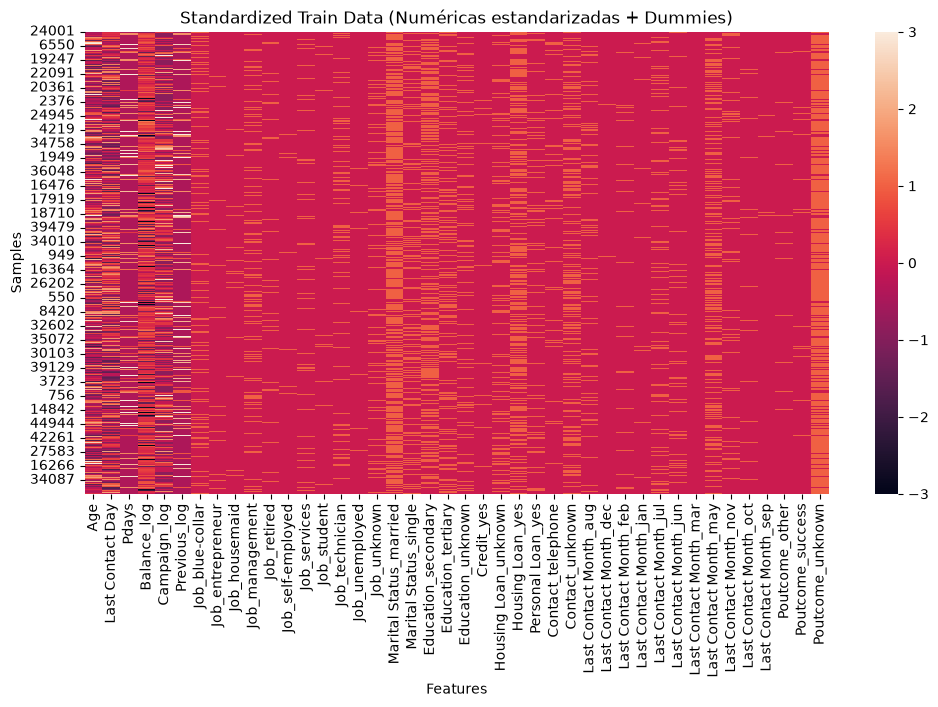

In [3]:
# Heatmap de los datos de entrenamiento ya procesados (Clase 03 / Clase 09)
plt.figure(figsize=(12, 6))
sns.heatmap(xtrain_scal, vmin=-3, vmax=3)
plt.title("Standardized Train Data (Numéricas estandarizadas + Dummies)")
plt.xlabel("Features")
plt.ylabel("Samples")
plt.show()

## Cómo evaluamos los modelos

### Por qué no usamos accuracy

El dataset está fuertemente desbalanceado: solo el 11,7% de los clientes suscribe. En este contexto, el *accuracy* (la proporción total de aciertos) es engañoso. Un modelo que prediga siempre "no suscribe", sin aprender nada, acertaría el 88,3% de los casos. Un accuracy alto no indica que el modelo detecte a los clientes que suscriben, que son justamente los que le interesan al banco.

### Métrica principal: AUC-ROC

Para comparar y elegir modelos usamos el área bajo la curva ROC (AUC-ROC).

- **La curva ROC** muestra, para cada threshold de decisión posible, la proporción de suscriptores que el modelo detecta (tasa de verdaderos positivos, en el eje Y) frente a la proporción de no suscriptores que marca como "suscribe" por error (tasa de falsos positivos, en el eje X).
- **El AUC** es el área bajo esa curva. Equivale a la probabilidad de que, tomando al azar un cliente que suscribió y uno que no, el modelo le asigne mayor probabilidad de suscripción al primero. Un AUC de 0,5 corresponde a un modelo que ordena al azar, y un AUC de 1, a uno que ordena perfectamente.

Elegimos el AUC-ROC por tres motivos:

1. **No depende del threshold.** Resume el desempeño sobre todos los thresholds posibles, por lo que mide la capacidad del modelo para separar ambas clases, independientemente de dónde se ubique el corte.
2. **No lo engaña el desbalance.** El modelo trivial que predice siempre "no suscribe" tiene un AUC de 0,5, aunque su accuracy sea de 88,3%.
3. **Responde al uso real del modelo.** El banco necesita una lista de clientes ordenada por propensión para priorizar sus llamadas, y el AUC mide justamente la calidad de ese orden.

Por eso, la búsqueda de hiperparámetros (`GridSearchCV`) usa `scoring='roc_auc'`, con validación cruzada de 5 folds. Para clasificadores, `GridSearchCV` estratifica los folds automáticamente, por lo que cada fold mantiene la proporción de suscriptores.

### Precision, recall y F1-score

Para tomar decisiones, el modelo debe aplicar un threshold: los clientes con probabilidad mayor a ese valor se predicen como "suscribe". En términos del banco, los cuatro resultados posibles de la matriz de confusión son:

| | Predice "no suscribe" (no se lo llama) | Predice "suscribe" (se lo llama) |
|---|---|---|
| **No suscribe** | Verdadero negativo (TN): no se gasta una llamada en vano | Falso positivo (FP): llamada sin resultado |
| **Suscribe** | Falso negativo (FN): suscripción perdida | Verdadero positivo (TP): suscripción lograda |

A partir de esta matriz, y para la clase `Suscribe (1)`, calculamos:

- **Recall** = TP / (TP + FN): de todos los clientes que suscribirían, ¿qué proporción detecta el modelo?
- **Precision** = TP / (TP + FP): de todos los clientes a los que el modelo indica llamar, ¿qué proporción suscribe?
- **F1-score** = 2 · Precision · Recall / (Precision + Recall): la media armónica de ambas, que resume el equilibrio entre las dos. Al ser una media armónica, queda cerca del valor más bajo: un modelo con buena precision pero recall muy bajo (o al revés) obtiene un F1 bajo.

Analizamos estas métricas para la clase `Suscribe (1)`, que es la que el banco busca identificar. Las de la clase `No suscribe (0)` son siempre altas por ser la mayoritaria y no permiten distinguir entre modelos. Por el mismo motivo, en el `classification_report` el promedio `weighted avg` está dominado por la clase mayoritaria y resulta engañoso, igual que el accuracy.

### Supuesto de costos

Asumimos que, para el banco, **es más costoso no llamar a un cliente que habría suscripto (falso negativo) que llamar a un cliente que no suscribirá (falso positivo)**. Un falso negativo implica perder una suscripción y el ingreso asociado. Un falso positivo solo implica el costo de una llamada.

En consecuencia, **priorizamos un recall alto en la clase `Suscribe`**, aceptando una precision menor, es decir, más llamadas sin resultado a cambio de perder menos suscripciones. La precision, sin embargo, no puede caer sin límite. En el extremo, llamar a todos los clientes alcanza un recall de 1, pero con una precision igual a la tasa de suscripción (11,7%), y esa estrategia no requiere ningún modelo. El valor del modelo está en reducir la cantidad de llamadas sin perder demasiadas suscripciones.

Por este supuesto, el F1-score, que le asigna el mismo peso a la precision y al recall (es decir, asume que ambos errores cuestan lo mismo), nos sirve como referencia del equilibrio entre ambas, pero no como criterio de decisión.

### Sobre el threshold

Precision, recall y F1 dependen del threshold, que por defecto es 0,5 en el método `predict`. Ese valor no es adecuado para un target desbalanceado. Además, los modelos que usan `class_weight='balanced'` producen probabilidades infladas hacia la clase minoritaria, por lo que el mismo threshold de 0,5 tiene un efecto distinto en cada modelo.

Por eso seguimos este procedimiento:

1. **Elegir el modelo según el AUC-ROC** de validación cruzada, que no depende del threshold.
2. **Ajustar el threshold del modelo elegido** según el supuesto de costos, usando únicamente datos de entrenamiento.
3. **Evaluar el resultado final en test** con la matriz de confusión, precision, recall y F1 de la clase `Suscribe`.

En las secciones siguientes, el `classification_report` de cada modelo se calcula con el threshold de 0,5. Lo usamos para describir su comportamiento, pero no para compararlos entre sí.

**Regresión Logística**

In [4]:
# Definimos el modelo base de Regresión Logística
# Usamos class_weight='balanced' (visto en Clase 05) porque la clase positiva es solo el 11.7%
log_reg = LogisticRegression(solver='liblinear', class_weight='balanced', max_iter=1000, random_state=42)

# Grilla de hiperparámetros (siguiendo Clase 04)
param_lr = {
    'C': [0.01, 0.1, 1, 10, 100],
    'penalty': ['l1', 'l2']
}

# Definimos el GridSearchCV con 5 folds
# Usamos scoring='roc_auc' para evaluar el poder de discriminación real ante clases desbalanceadas
clf_lr = GridSearchCV(
    log_reg, 
    param_grid=param_lr, 
    cv=5, 
    scoring='roc_auc',
    n_jobs=-1
)

# Entrenamos con los datos de train escalados
clf_lr.fit(xtrain_scal, ytrain)

print("Mejores hiperparámetros encontrados:", clf_lr.best_params_)
print(f"Mejor AUC-ROC en Cross-Validation (Train): {clf_lr.best_score_:.4f}")

Mejores hiperparámetros encontrados: {'C': 0.1, 'penalty': 'l1'}
Mejor AUC-ROC en Cross-Validation (Train): 0.7642


Accuracy en Test: 0.7586
AUC-ROC en Test: 0.7724

                 precision    recall  f1-score   support

No suscribe (0)      0.942     0.775     0.850      7985
   Suscribe (1)      0.273     0.638     0.382      1058

       accuracy                          0.759      9043
      macro avg      0.607     0.706     0.616      9043
   weighted avg      0.863     0.759     0.795      9043



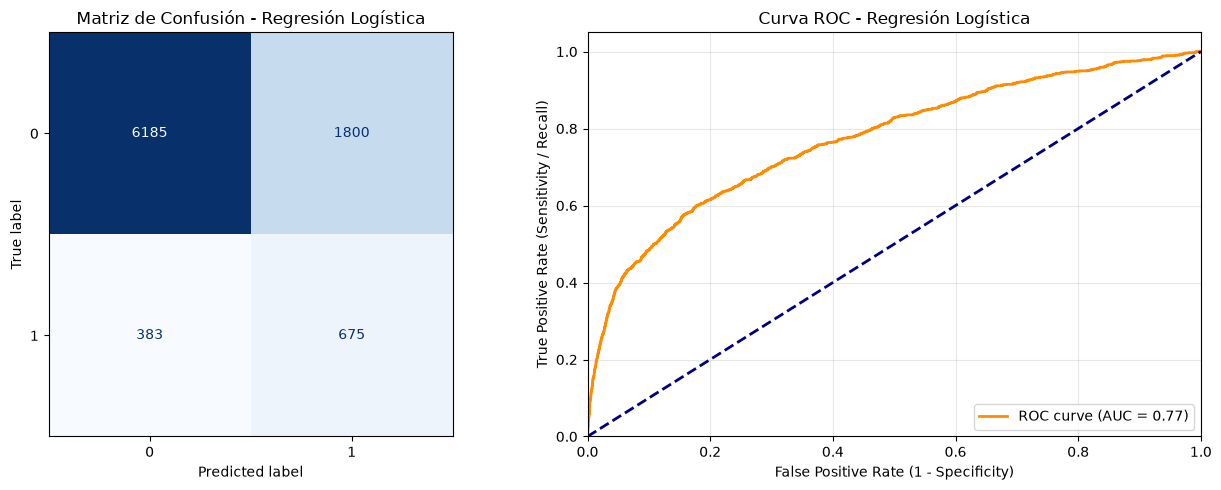

In [5]:
# Predicciones de etiqueta (0 o 1) y de probabilidad sobre el conjunto de Test
ypred_lr = clf_lr.predict(xtest_scal)
yproba_lr = clf_lr.predict_proba(xtest_scal)

# Calculamos Accuracy y Curva ROC (usando la probabilidad de la clase positiva yproba_lr[:, 1] como en Clase 03)
acc_lr = accuracy_score(ytest, ypred_lr)
fpr_lr, tpr_lr, thresholds_lr = roc_curve(ytest, yproba_lr[:, 1])
auc_lr = auc(fpr_lr, tpr_lr)

print(f"Accuracy en Test: {acc_lr:.4f}")
print(f"AUC-ROC en Test: {auc_lr:.4f}\n")
print(classification_report(ytest, ypred_lr, target_names=clases, digits=3))

# Graficamos Matriz de Confusión y Curva ROC lado a lado
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

# 1. Matriz de Confusión
cm_lr = confusion_matrix(ytest, ypred_lr)
disp_lr = ConfusionMatrixDisplay(confusion_matrix=cm_lr, display_labels=clf_lr.classes_)
disp_lr.plot(ax=ax[0], cmap='Blues', colorbar=False)
ax[0].set_title("Matriz de Confusión - Regresión Logística")

# 2. Curva ROC (Clase 03)
ax[1].plot(fpr_lr, tpr_lr, color='darkorange', lw=2, label=f'ROC curve (AUC = {auc_lr:.2f})')
ax[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
ax[1].set_xlim([0.0, 1.0])
ax[1].set_ylim([0.0, 1.05])
ax[1].set_xlabel('False Positive Rate (1 - Specificity)')
ax[1].set_ylabel('True Positive Rate (Sensitivity / Recall)')
ax[1].set_title('Curva ROC - Regresión Logística')
ax[1].legend(loc="lower right")
ax[1].grid( alpha=0.3)

plt.tight_layout()
plt.show()

### Conclusión: regresión logística

- **Hiperparámetros:** el mejor modelo usa `C = 0.1` con penalización L1, es decir, una regularización fuerte que puede llevar a cero los coeficientes de las variables menos informativas.
- **Capacidad de discriminación:** el AUC es de 0,764 en validación cruzada y de 0,772 en test. Ambos valores son consistentes, sin señales de sobreajuste.
- **Comportamiento con threshold 0,5:** por `class_weight='balanced'`, el modelo es "generoso" con la clase positiva. Indica llamar a 2.475 clientes (27,4% del test) y detecta a 675 de los 1.058 suscriptores (**recall de 63,8%**). Su **precision es de 27,3%**: algo más de 1 de cada 4 llamadas termina en suscripción, más del doble de la tasa base (11,7%). Quedan 383 suscriptores sin llamar.
- **Sobre el accuracy:** su accuracy (75,9%) es inferior al del modelo trivial que predice siempre "no suscribe" (88,3%). Esto no lo hace un peor modelo: es la consecuencia de priorizar la detección de la clase minoritaria, y muestra por qué el accuracy no sirve para este problema.

Bajo nuestro supuesto de costos, su perfil (recall alto, precision baja) va en la dirección correcta, aunque con muchas llamadas sin resultado.

**KNN**

In [6]:
# Definimos el clasificador KNN (Clases 03, 04 y 06)
knn = KNeighborsClassifier()

# Grilla de hiperparámetros siguiendo el esquema de Clase 04 y Clase 06
param_knn = {
    'n_neighbors': [5, 15, 31, 51, 100, 200, 300, 400],
    'weights': ['uniform', 'distance']
}

# Usamos n_jobs=2 para usar solo 2 núcleos y no saturar el CPU ni la RAM
clf_knn = GridSearchCV(
    knn, 
    param_grid=param_knn, 
    cv=5, 
    scoring='roc_auc',
    n_jobs=-2
)

# Entrenamos con los datos de train escalados
clf_knn.fit(xtrain_scal, ytrain)

print("Mejores hiperparámetros encontrados:", clf_knn.best_params_)
print(f"Mejor AUC-ROC en Cross-Validation (Train): {clf_knn.best_score_:.4f}")

Mejores hiperparámetros encontrados: {'n_neighbors': 200, 'weights': 'distance'}
Mejor AUC-ROC en Cross-Validation (Train): 0.7612


Accuracy en Test: 0.8852
AUC-ROC en Test: 0.7724

                 precision    recall  f1-score   support

No suscribe (0)      0.885     0.999     0.939      7985
   Suscribe (1)      0.833     0.024     0.046      1058

       accuracy                          0.885      9043
      macro avg      0.859     0.512     0.492      9043
   weighted avg      0.879     0.885     0.834      9043



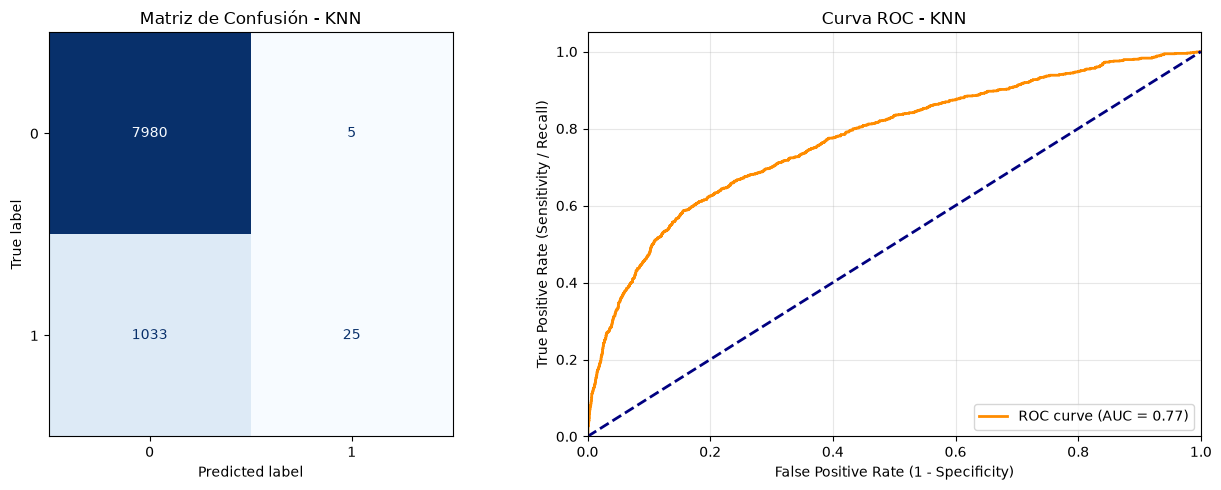

In [7]:
# Predicciones de etiqueta (0 o 1) y de probabilidad sobre el conjunto de Test
ypred_knn = clf_knn.predict(xtest_scal)
yproba_knn = clf_knn.predict_proba(xtest_scal)

# Calculamos Accuracy y Curva ROC (Clase 03)
acc_knn = accuracy_score(ytest, ypred_knn)
fpr_knn, tpr_knn, thresholds_knn = roc_curve(ytest, yproba_knn[:, 1])
auc_knn = auc(fpr_knn, tpr_knn)

print(f"Accuracy en Test: {acc_knn:.4f}")
print(f"AUC-ROC en Test: {auc_knn:.4f}\n")
print(classification_report(ytest, ypred_knn, target_names=clases, digits=3))

# Graficamos Matriz de Confusión y Curva ROC lado a lado
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

# 1. Matriz de Confusión
cm_knn = confusion_matrix(ytest, ypred_knn)
disp_knn = ConfusionMatrixDisplay(confusion_matrix=cm_knn, display_labels=clf_knn.classes_)
disp_knn.plot(ax=ax[0], cmap='Blues', colorbar=False)
ax[0].set_title("Matriz de Confusión - KNN")

# 2. Curva ROC
ax[1].plot(fpr_knn, tpr_knn, color='darkorange', lw=2, label=f'ROC curve (AUC = {auc_knn:.2f})')
ax[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
ax[1].set_xlim([0.0, 1.0])
ax[1].set_ylim([0.0, 1.05])
ax[1].set_xlabel('False Positive Rate (1 - Specificity)')
ax[1].set_ylabel('True Positive Rate (Sensitivity / Recall)')
ax[1].set_title('Curva ROC - KNN')
ax[1].legend(loc="lower right")
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Conclusión: KNN

- **Hiperparámetros:** en una primera búsqueda, el mejor valor de `k` quedó en el límite superior de la grilla (51), por lo que la ampliamos hasta 400 vecinos. El mejor modelo usa `k = 200` vecinos ponderados por distancia. Como valores mayores (300 y 400) no mejoraron el resultado, el óptimo queda dentro del rango explorado. Que el mejor `k` sea tan alto indica que conviene "suavizar" la estimación promediando sobre vecindarios amplios: con pocos vecinos, la proporción de suscriptores es muy ruidosa.
- **Capacidad de discriminación:** el AUC es de 0,761 en validación cruzada y de 0,772 en test, igual al de la regresión logística en test.
- **Comportamiento con threshold 0,5:** el contraste con la regresión logística es extremo. El modelo indica llamar solo a 30 clientes (0,3% del test). Acierta en casi todos (**precision de 83,3%**), pero detecta apenas a 25 de los 1.058 suscriptores (**recall de 2,4%**), y deja 1.033 sin llamar. Su accuracy (88,5%) es prácticamente igual al del modelo trivial que predice siempre "no suscribe".
- **Por qué:** KNN no admite `class_weight`. Su probabilidad es la proporción (ponderada por distancia) de suscriptores entre los 200 vecinos más cercanos. Como solo el 11,7% de los clientes suscribe, para superar 0,5 un cliente necesita que más de la mitad de sus 200 vecinos haya suscripto, algo que casi nunca ocurre: la probabilidad máxima que asigna el modelo en test es de 0,56. Cuanto mayor es `k`, más se acercan las probabilidades a la tasa general y menos clientes superan el 0,5. Por eso, al pasar de 51 a 200 vecinos, el AUC mejora levemente, pero el recall con threshold 0,5 cae del 7,5% al 2,4%.

Como su AUC es igual al de la regresión logística, el problema no está en su capacidad para ordenar a los clientes, sino en el threshold. Con un threshold más bajo, su desempeño sería comparable. Bajo nuestro supuesto de costos, con threshold 0,5 es el peor de los modelos, porque pierde casi todas las suscripciones.

Arbol de decisión

In [8]:
# Definimos el modelo base de Árbol de Decisión (Clase 06 - Titanic)

tree_model = DecisionTreeClassifier(class_weight='balanced', random_state=42)

# Grilla de hiperparámetros exacta de Clase 06 (Titanic)
param_tree = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [5, 10, 15],
    'min_samples_leaf': [1, 4, 6]
}

# GridSearchCV con 5 folds
clf_tree = GridSearchCV(
    estimator=tree_model,
    param_grid=param_tree,
    cv=5,
    scoring='roc_auc',
    n_jobs=-2
)

# Entrenamos con los datos de train escalados
clf_tree.fit(xtrain_scal, ytrain)

print("Mejores hiperparámetros encontrados:", clf_tree.best_params_)
print(f"Mejor AUC-ROC en Cross-Validation (Train): {clf_tree.best_score_:.4f}")

Mejores hiperparámetros encontrados: {'criterion': 'entropy', 'max_depth': 10, 'min_samples_leaf': 6}
Mejor AUC-ROC en Cross-Validation (Train): 0.7390


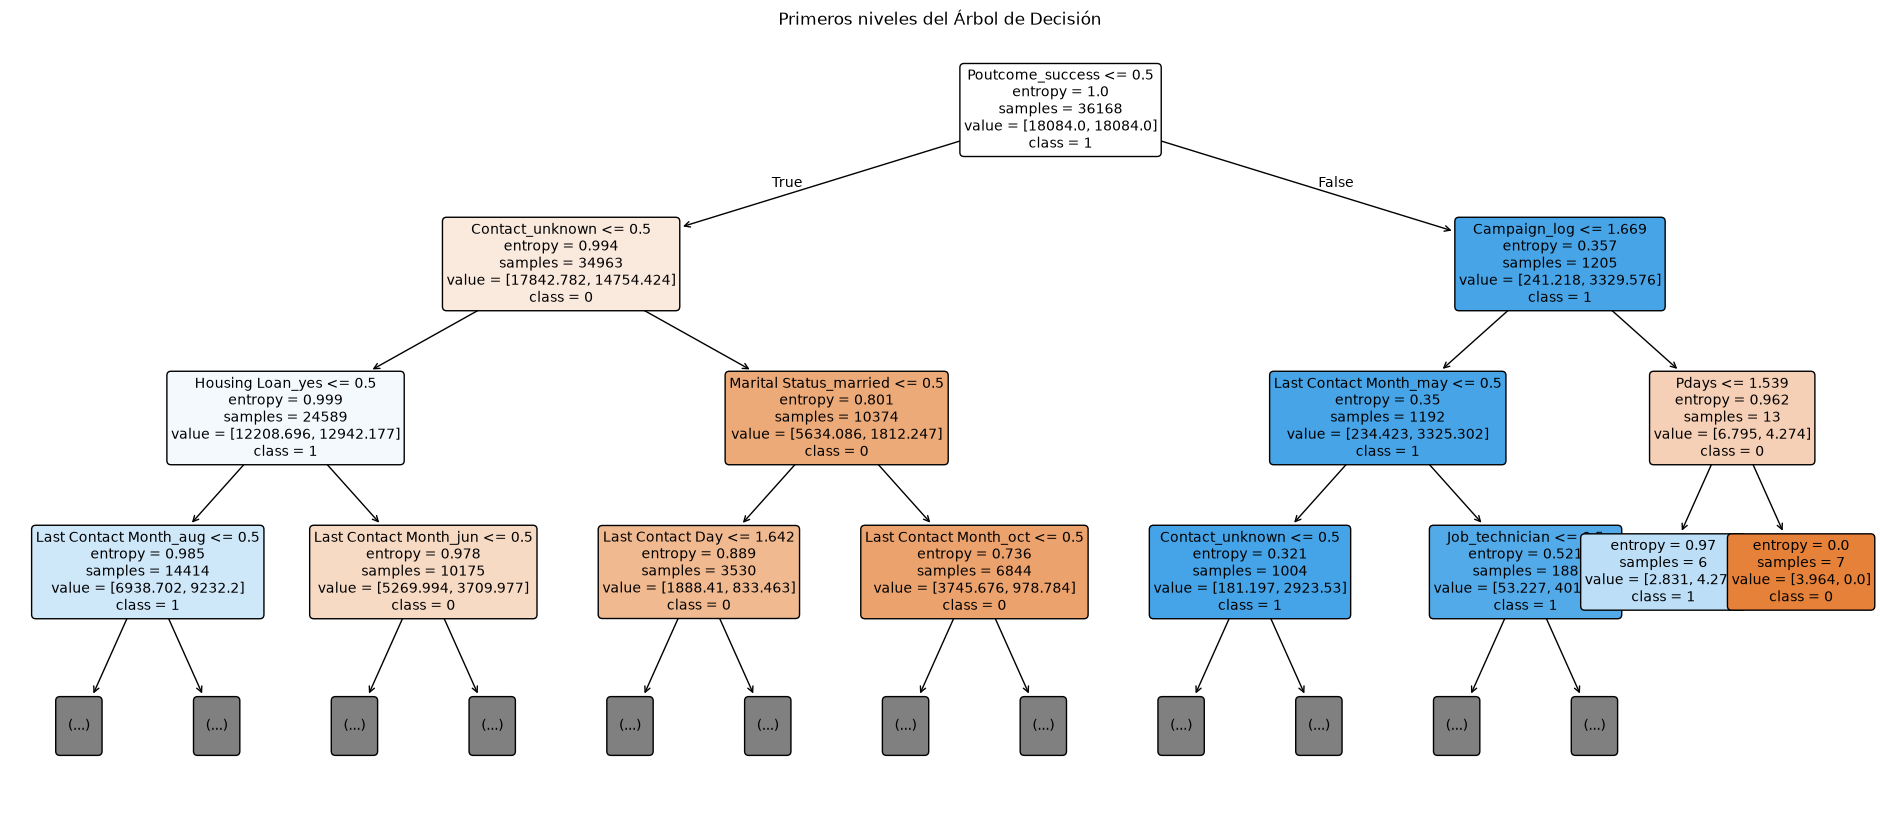

In [9]:
from sklearn import tree

plt.figure(figsize=(24, 10))
best_tree = clf_tree.best_estimator_

tree.plot_tree(
    best_tree,
    max_depth=3,
    feature_names=xtrain_scal.columns,
    class_names=[str(c) for c in best_tree.classes_],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Primeros niveles del Árbol de Decisión")
plt.show()

Accuracy en Test: 0.8290
AUC-ROC en Test: 0.7593

                 precision    recall  f1-score   support

No suscribe (0)      0.936     0.865     0.899      7985
   Suscribe (1)      0.353     0.556     0.432      1058

       accuracy                          0.829      9043
      macro avg      0.645     0.711     0.666      9043
   weighted avg      0.868     0.829     0.845      9043



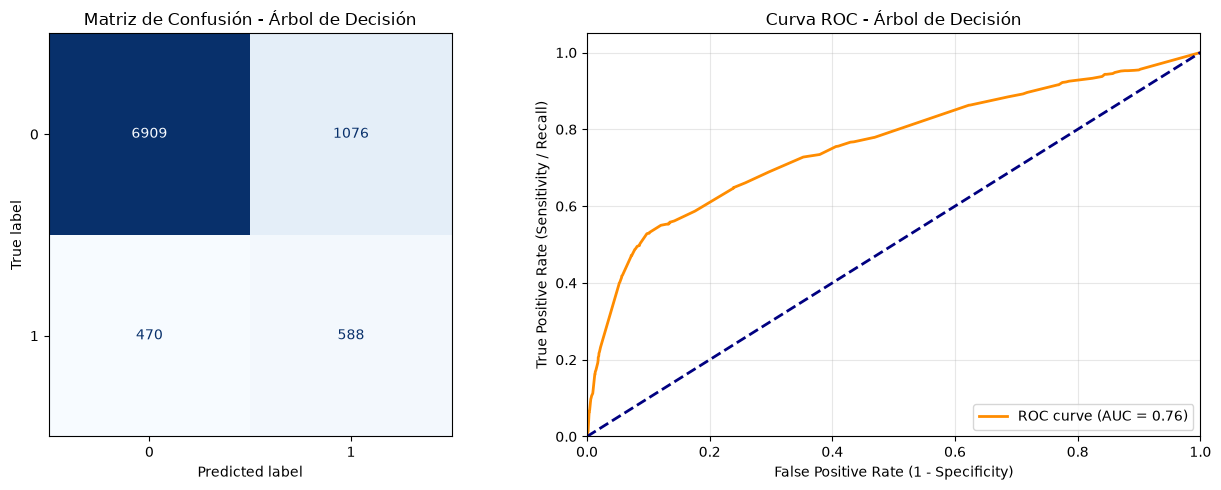

In [10]:
# Predicciones de etiqueta (0 o 1) y de probabilidad sobre el conjunto de Test
ypred_tree = clf_tree.predict(xtest_scal)
yproba_tree = clf_tree.predict_proba(xtest_scal)

# Calculamos Accuracy y Curva ROC (Clase 03 y Clase 06)
acc_tree = accuracy_score(ytest, ypred_tree)
fpr_tree, tpr_tree, thresholds_tree = roc_curve(ytest, yproba_tree[:, 1])
auc_tree = auc(fpr_tree, tpr_tree)

print(f"Accuracy en Test: {acc_tree:.4f}")
print(f"AUC-ROC en Test: {auc_tree:.4f}\n")
print(classification_report(ytest, ypred_tree, target_names=clases, digits=3))

# Graficamos Matriz de Confusión y Curva ROC lado a lado
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

# 1. Matriz de Confusión
cm_tree = confusion_matrix(ytest, ypred_tree)
disp_tree = ConfusionMatrixDisplay(confusion_matrix=cm_tree, display_labels=clf_tree.classes_)
disp_tree.plot(ax=ax[0], cmap='Blues', colorbar=False)
ax[0].set_title("Matriz de Confusión - Árbol de Decisión")

# 2. Curva ROC
ax[1].plot(fpr_tree, tpr_tree, color='darkorange', lw=2, label=f'ROC curve (AUC = {auc_tree:.2f})')
ax[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
ax[1].set_xlim([0.0, 1.0])
ax[1].set_ylim([0.0, 1.05])
ax[1].set_xlabel('False Positive Rate (1 - Specificity)')
ax[1].set_ylabel('True Positive Rate (Sensitivity / Recall)')
ax[1].set_title('Curva ROC - Árbol de Decisión')
ax[1].legend(loc="lower right")
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Conclusión: árbol de decisión

- **Hiperparámetros:** el mejor árbol usa el criterio de entropía, con profundidad máxima 10 y un mínimo de 6 observaciones por hoja (el valor más alto de la grilla). Estas restricciones limitan su complejidad y reducen el sobreajuste.
- **Capacidad de discriminación:** el AUC es de 0,739 en validación cruzada y de 0,759 en test, el más bajo de los cuatro modelos. Un único árbol es un modelo de alta varianza: pequeños cambios en los datos pueden cambiar mucho su estructura.
- **Interpretabilidad:** el primer corte del árbol es `Poutcome_success`, es decir, si el cliente suscribió en la campaña anterior. Esto coincide con el EDA, donde esa fue la variable más asociada a la suscripción (64,7% de tasa de suscripción contra 11,7% general). Es la principal ventaja del árbol: sus reglas se pueden leer y explicar al negocio.
- **Comportamiento con threshold 0,5:** indica llamar a 1.664 clientes (18,4% del test) y detecta a 588 de los 1.058 suscriptores (**recall de 55,6%**), con una **precision de 35,3%**. Quedan 470 suscriptores sin llamar. Frente a la regresión logística, llama a menos clientes con mejor precision, pero pierde más suscriptores.

Random Forest

In [11]:
# Definimos el modelo base de Random Forest (Clase 06 - Titanic)
rf = RandomForestClassifier(class_weight='balanced', random_state=42)

# Grilla de 4 hiperparámetros siguiendo Clase 06 (Titanic)
param_rf = {
    'n_estimators': [100, 200],
    'max_depth': [5, 10, 15],
    'criterion': ['gini', 'entropy'],
    'min_samples_leaf': [1, 4, 6]
}

# Definimos el GridSearchCV con 5 folds y n_jobs=-2 para cuidar el CPU
clf_rf = GridSearchCV(
    estimator=rf, 
    param_grid=param_rf, 
    cv=5, 
    scoring='roc_auc',
    n_jobs=-2
)

# Entrenamos con los datos de train escalados
clf_rf.fit(xtrain_scal, ytrain)

print("Mejores hiperparámetros encontrados:", clf_rf.best_params_)
print(f"Mejor AUC-ROC en Cross-Validation (Train): {clf_rf.best_score_:.4f}")

Mejores hiperparámetros encontrados: {'criterion': 'entropy', 'max_depth': 15, 'min_samples_leaf': 4, 'n_estimators': 200}
Mejor AUC-ROC en Cross-Validation (Train): 0.7918


In [12]:
# Evaluación en Test del Random Forest
ypred_rf1 = clf_rf.predict(xtest_scal)
yproba_rf1 = clf_rf.predict_proba(xtest_scal)
acc_rf1 = accuracy_score(ytest, ypred_rf1)
fpr_rf1, tpr_rf1, _ = roc_curve(ytest, yproba_rf1[:, 1])
auc_rf1 = auc(fpr_rf1, tpr_rf1)

print(f"Accuracy en Test: {acc_rf1:.4f}")
print(f"AUC-ROC en Test:  {auc_rf1:.4f}\n")
print(classification_report(ytest, ypred_rf1, target_names=clases, digits=3))

Accuracy en Test: 0.8316
AUC-ROC en Test:  0.8005

                 precision    recall  f1-score   support

No suscribe (0)      0.944     0.861     0.900      7985
   Suscribe (1)      0.368     0.612     0.459      1058

       accuracy                          0.832      9043
      macro avg      0.656     0.736     0.680      9043
   weighted avg      0.876     0.832     0.849      9043



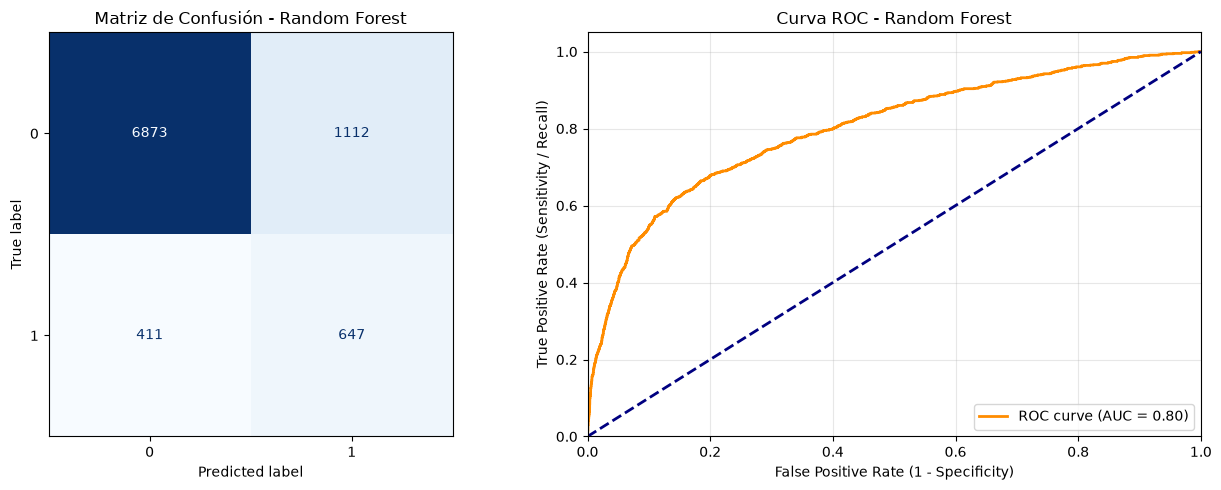

In [13]:
# Graficamos Matriz de Confusión y Curva ROC lado a lado para el Random Forest
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

# 1. Matriz de Confusión
cm_rf1 = confusion_matrix(ytest, ypred_rf1)
disp_rf1 = ConfusionMatrixDisplay(confusion_matrix=cm_rf1, display_labels=clf_rf.classes_)
disp_rf1.plot(ax=ax[0], cmap='Blues', colorbar=False)
ax[0].set_title("Matriz de Confusión - Random Forest")

# 2. Curva ROC
ax[1].plot(fpr_rf1, tpr_rf1, color='darkorange', lw=2, label=f'ROC curve (AUC = {auc_rf1:.2f})')
ax[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
ax[1].set_xlim([0.0, 1.0])
ax[1].set_ylim([0.0, 1.05])
ax[1].set_xlabel('False Positive Rate (1 - Specificity)')
ax[1].set_ylabel('True Positive Rate (Sensitivity / Recall)')
ax[1].set_title('Curva ROC - Random Forest')
ax[1].legend(loc="lower right")
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Conclusión: Random Forest

- **Hiperparámetros:** el mejor modelo usa 200 árboles con criterio de entropía, profundidad máxima 15 y un mínimo de 4 observaciones por hoja. La profundidad máxima y la cantidad de árboles quedaron en el límite superior de la grilla, por lo que ampliar esos rangos podría mejorar levemente el resultado, a costa de un entrenamiento más lento.
- **Capacidad de discriminación:** el AUC es de 0,792 en validación cruzada y de 0,801 en test, **el mejor de todos los modelos**, unos 0,03 por encima del resto. Al promediar cientos de árboles entrenados sobre muestras distintas, el Random Forest reduce la varianza de un árbol individual (de 0,759 a 0,801 de AUC en test) y captura relaciones no lineales e interacciones entre variables que la regresión logística no modela.
- **Sobreajuste:** el AUC de test es similar al de validación cruzada, por lo que no hay señales de sobreajuste relevante.
- **Comportamiento con threshold 0,5:** indica llamar a 1.759 clientes (19,5% del test) y detecta a 647 de los 1.058 suscriptores (**recall de 61,2%**), con una **precision de 36,8%** y el **mejor F1 (0,459)**. Quedan 411 suscriptores sin llamar. En términos del negocio, llamando a 1 de cada 5 clientes, el banco alcanzaría a más del 60% de los suscriptores: unas 3 veces lo que lograría llamando a la misma cantidad de clientes al azar.
- **Desventajas:** es menos interpretable que un árbol individual o que la regresión logística, y su entrenamiento es el más costoso.

## Conclusiones generales

| Modelo | AUC CV | AUC test | Precision (1) | Recall (1) | F1 (1) | Llamadas (% test) |
|---|---|---|---|---|---|---|
| Regresión logística | 0,764 | 0,772 | 0,273 | 0,638 | 0,382 | 27,4% |
| KNN | 0,761 | 0,772 | 0,833 | 0,024 | 0,046 | 0,3% |
| Árbol de decisión | 0,739 | 0,759 | 0,353 | 0,556 | 0,432 | 18,4% |
| **Random Forest** | **0,792** | **0,801** | 0,368 | 0,612 | **0,459** | 19,5% |

*Precision, recall y F1 corresponden a la clase `Suscribe (1)` con threshold 0,5.*

1. **El Random Forest es el mejor modelo.** Obtiene el AUC más alto tanto en validación cruzada como en test, con una ventaja de unos 0,03 sobre el resto. Lo elegimos por su AUC de validación cruzada, la métrica que definimos como criterio de selección.
2. **Los otros tres modelos tienen una capacidad de discriminación similar** (AUC entre 0,74 y 0,77 en validación cruzada). Las grandes diferencias que muestran con threshold 0,5 no reflejan diferencias en su calidad, sino en la escala de sus probabilidades. Los modelos con `class_weight='balanced'` producen probabilidades infladas y llaman a muchos clientes, mientras que KNN, sin pesos, casi nunca supera el 0,5. El caso de la regresión logística y el KNN lo muestra con claridad: el mismo AUC en test (0,772), pero recall de 63,8% contra 2,4%.
3. **El accuracy confirma ser una métrica engañosa.** El KNN tiene el accuracy más alto (88,5%) y es, a la vez, el modelo que menos suscriptores detecta.
4. **El desempeño es razonable para el problema.** Sin `Last Contact Duration` (excluida por *data leakage*), el mejor modelo alcanza un AUC de 0,80. Esto es coherente con el EDA, donde las variables continuas mostraron una asociación débil con el target y la señal se concentró en unas pocas variables, sobre todo el resultado de la campaña anterior (`Poutcome`).
5. **El threshold de 0,5 no es adecuado para ningún modelo.** Bajo nuestro supuesto de costos, el threshold debe ajustarse para el modelo elegido.

**Próximos pasos:** aplicar reducción de dimensionalidad (PCA) y volver a entrenar los modelos para comparar los resultados; ajustar el threshold del Random Forest según el supuesto de costos, usando validación cruzada sobre train; y evaluar el modelo final en test.

## Reducción de la dimensionalidad 
El objetivo es reducir las 42 variables con PCA para identificar las dimensiones que representan realmente las variaciones y volver a predecir solamente con las dimensiones de mayor variabilidad. 
Como un paso previo se debe hacer el escalamiento para que las variables dummies equivalgan en desvío al resto. 

In [14]:
scaler_pca = StandardScaler()
scaler_pca.fit(xtrain_scal)
xtrain_std = scaler_pca.transform(xtrain_scal)  
xtest_std = scaler_pca.transform(xtest_scal)  
print(xtrain_std.mean(axis=0).round(2), xtrain_std.std(axis=0).round(2))

[ 0.  0.  0.  0.  0. -0. -0. -0.  0. -0.  0.  0. -0. -0.  0.  0.  0.  0.
  0. -0. -0. -0.  0. -0.  0.  0. -0. -0. -0. -0. -0.  0.  0. -0.  0.  0.
  0.  0.  0.  0.  0. -0.] [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [15]:
# cantidad de componentes a extraer
n_comps = 42
# definimos PCA
pca = PCA(n_components= n_comps)
# fit_transform del PCA a nuestros datos
xpca = pd.DataFrame(pca.fit_transform(xtrain_std))
# obtenemos los auto-valores
eigenvalues = pca.explained_variance_ratio_
xpca_test = pd.DataFrame(pca.transform(xtest_std))

In [16]:
pca.explained_variance_

array([3.44381762, 2.50577431, 2.23806455, 1.86986238, 1.66921581,
       1.40414074, 1.37327146, 1.30610471, 1.27935352, 1.22481112,
       1.18639537, 1.15368354, 1.12971333, 1.12172063, 1.09527568,
       1.07651053, 1.03801584, 1.0349924 , 1.0249501 , 1.01923317,
       1.01510438, 1.00715111, 0.99194429, 0.96812264, 0.93277283,
       0.89458026, 0.86206366, 0.82759164, 0.78385172, 0.75499778,
       0.64227455, 0.5813089 , 0.53737224, 0.51452749, 0.41206629,
       0.27587249, 0.20178508, 0.19808063, 0.15979507, 0.10971038,
       0.07227174, 0.0630093 ])

In [17]:
pca.explained_variance_ratio_

array([0.08199339, 0.05965964, 0.05328578, 0.0445193 , 0.03974213,
       0.033431  , 0.03269604, 0.03109687, 0.03045996, 0.02916136,
       0.02824673, 0.0274679 , 0.02689719, 0.0267069 , 0.02607727,
       0.02563049, 0.02471398, 0.02464199, 0.0244029 , 0.02426679,
       0.02416848, 0.02397913, 0.02361707, 0.0230499 , 0.02220826,
       0.02129894, 0.02052476, 0.01970402, 0.01866262, 0.01797564,
       0.01529183, 0.01384031, 0.01279422, 0.01225032, 0.00981083,
       0.00656821, 0.00480427, 0.00471608, 0.00380454, 0.00261208,
       0.00172071, 0.00150018])

La variabilidad esta muy repartida entre los componentes, no hay pocas que concentren mucha variabilidad. PC1 explica solo el 8,2% y hacen falta muchas componentes para acumular una proporción alta.

In [18]:
# observamos el shape de la matriz obtenida del PCA. PCA con todas las componentes: rota los ejes sin reducir
xpca.shape

(36168, 42)

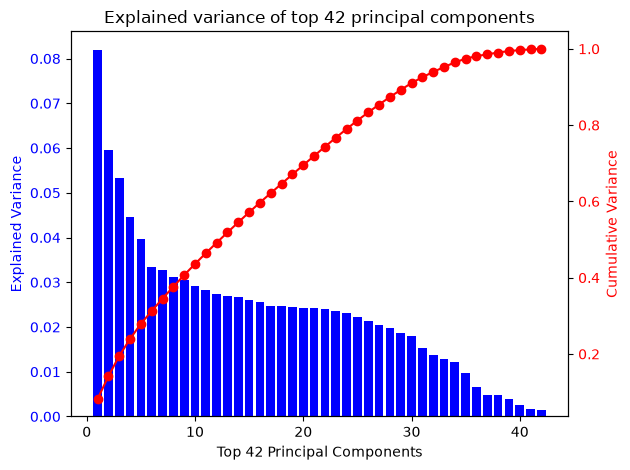

In [19]:
fig, ax1 = plt.subplots()

components = range(1, n_comps + 1)

# Graficar las barras de varianza explicada en el eje izquierdo
ax1.bar(components, eigenvalues, label='Explained Variance', color='blue')
ax1.set_xlabel('Top ' + str(n_comps) + ' Principal Components')
ax1.set_ylabel('Explained Variance', color='blue')
ax1.tick_params(axis='y', labelcolor='blue')

# Crear un segundo eje para la varianza acumulada
ax2 = ax1.twinx()
cumulative_variance = np.cumsum(eigenvalues) / np.sum(eigenvalues)

# Graficar la varianza acumulada en el eje derecho
ax2.plot(components, cumulative_variance, color='red', marker='o', label='Cumulative Variance')
ax2.set_ylabel('Cumulative Variance', color='red')
ax2.tick_params(axis='y', labelcolor='red')

# Configurar el título y las leyendas
plt.title('Explained variance of top ' + str(n_comps) + ' principal components')

fig.tight_layout()  # Ajustar el layout para que no se superpongan los ejes
plt.show()


Para retener el 80% de la variabilidad se requieren 25 componentes y para el 90% se requieren 30 componentes, de los 42 totales. La reducción posible es baja, sacar el 40% de las dimensiones y perder 20% de variabilidad.
Está de acuerdo con el EDA donde se veía una baja correlación entre las variables.

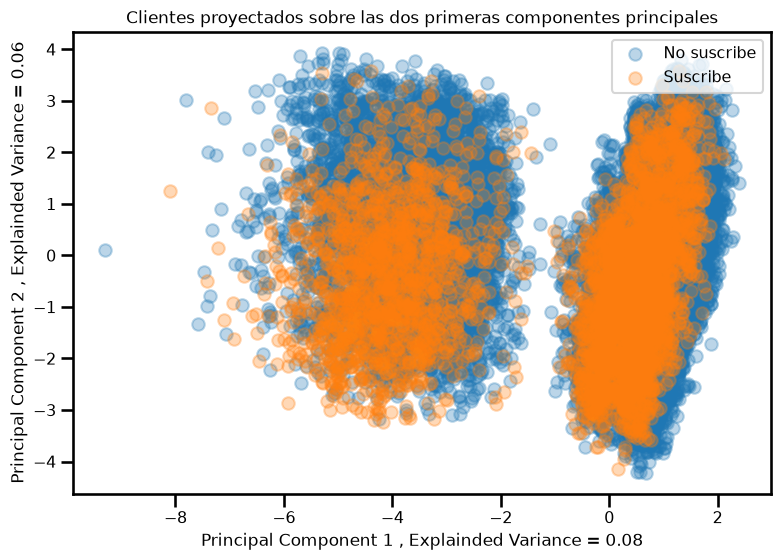

In [20]:
sns.set_context("talk", font_scale=0.7)
plt.figure(figsize=(9,6))
plt.scatter(xpca.loc[(ytrain == 0).values,0],xpca.loc[(ytrain == 0).values,1], alpha = 0.3, label = 'No suscribe')
plt.scatter(xpca.loc[(ytrain == 1).values,0],xpca.loc[(ytrain == 1).values,1], alpha = 0.3, label = 'Suscribe')
plt.xlabel('Principal Component 1 , Explainded Variance = ' + str(np.round(eigenvalues[0],2)))
plt.ylabel('Principal Component 2 , Explainded Variance = ' + str(np.round(eigenvalues[1],2)))
plt.title('Clientes proyectados sobre las dos primeras componentes principales')
plt.legend(loc='upper right')
plt.show()

Las componentes PC1 y PC2 no separan a los clientes que suscriben de los que no. Concentran solo el 14% de la variabilidad. Sin embargo PC1 divide a los clientes en dos grupos, lo que indica que capta alguna característica que separa perfiles. Dentro de cada grupo, los clientes que suscriben y los que no aparecen superpuestos, por lo que con estas dos componentes no es posible diferenciarlos.
Esto es esperable porque PCA busca las direcciones de mayor variabilidad sin usar la variable objetivo. No garantiza que esas direcciones separen a quienes suscriben.
El EDA anticipó una explicación para los grupos. El historial de contacto con el banco resultó el factor más determinante para la suscripción, y Pdays y Previous fueron el único par de variables con correlación moderada ya que ambas distinguen a los clientes contactados en campañas anteriores de los que no. Entonces PC1 también relevó esa distinción. 

In [21]:
# De la libreria:
# 'Principal axes in feature space, representing the directions of maximum variance in the data'
# The components are sorted by explained_variance_
pd.DataFrame(pca.components_[0:3, :], columns=xtrain_scal.columns).T.round(2)

# En criollo:
# Es la direccion de los ejes de cada componente (autovectores)

,0,1,2
Age,0.01,-0.18,-0.41
Last Contact Day,0.06,-0.09,0.01
Pdays,-0.46,0.12,-0.06
Balance_log,-0.07,-0.11,-0.01
Campaign_log,0.09,-0.10,-0.02
Previous_log,-0.48,0.07,-0.06
Job_blue-collar,0.05,0.25,-0.14
Job_entrepreneur,0.01,-0.02,-0.02
Job_housemaid,0.02,-0.06,-0.08
Job_management,-0.05,-0.28,0.22


Los autovectores muestran el peso de cada variable original en cada componente. PC1 está formada principalmente por Poutcome_unknown (0,51), Previous (-0,48) y Pdays (-0,46), las tres variables que describen el historial de contacto. Esto confirma lo que anticipaba el EDA, los dos grupos del gráfico anterior corresponden a los clientes contactados en campañas anteriores y a los que nunca lo fueron. PC2 combina el mes de contacto (mayo, 0,39), el préstamo hipotecario (0,34) y la educación terciaria (-0,34). PC3 refleja la etapa de vida del cliente: soltero (0,53), casado (-0,49) y edad (-0,41).

### Conclusión de PCA
Según el gráfico de varianza acumulada, 25 componentes retienen el 80% de la variabilidad y 30 componentes retienen el 90%, de las 42 originales. La reducción es moderada, porque las variables comparten poca información entre sí. Tomamos 25 y 30 como valores candidatos para volver a entrenar los modelos. La elección final de la cantidad de componentes se hace con GridSearchCV, eligiendo la que mejor predice en validación cruzada.

## Modelos con PCA

Volvemos a entrenar los cuatro modelos usando las componentes principales en lugar de las 42 variables originales. Siguiendo la conclusión anterior, la cantidad de componentes (25 o 30) se elige con `GridSearchCV` junto con los hiperparámetros de cada modelo, maximizando el AUC-ROC en validación cruzada.

El escalado y el PCA se incluyen dentro de un `Pipeline` (escalado → PCA → modelo). Así, en cada fold de la validación cruzada el `StandardScaler` y el PCA se ajustan solo con los datos de entrenamiento de ese fold, y el fold de validación no interviene en el cálculo de las componentes. Si usáramos directamente las componentes de la sección anterior (calculadas con todo train), la validación cruzada estaría usando información de los folds de validación.

Usamos las mismas grillas de hiperparámetros que en los modelos sin PCA, para que la única diferencia sea la reducción de la dimensionalidad.

In [22]:
from sklearn.pipeline import Pipeline

# Cantidades de componentes candidatas (conclusión de la sección de PCA)
componentes_candidatas = [25, 30]

def grilla_con_pca(param_modelo):
    """Agrega la cantidad de componentes a la grilla de un modelo.
    En un Pipeline, los hiperparámetros se nombran 'paso__parametro'."""
    grilla = {'pca__n_components': componentes_candidatas}
    for nombre, valores in param_modelo.items():
        grilla['modelo__' + nombre] = valores
    return grilla

def evaluar_en_test(clf, nombre):
    """Reporte de clasificación, matriz de confusión y curva ROC en test (mismo formato que sin PCA)."""
    ypred = clf.predict(xtest_scal)
    yproba = clf.predict_proba(xtest_scal)[:, 1]
    fpr, tpr, _ = roc_curve(ytest, yproba)
    auc_test = auc(fpr, tpr)

    print(f"Accuracy en Test: {accuracy_score(ytest, ypred):.4f}")
    print(f"AUC-ROC en Test:  {auc_test:.4f}\n")
    print(classification_report(ytest, ypred, target_names=clases, digits=3))

    fig, ax = plt.subplots(1, 2, figsize=(13, 5))

    # 1. Matriz de Confusión
    disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(ytest, ypred), display_labels=clf.classes_)
    disp.plot(ax=ax[0], cmap='Blues', colorbar=False)
    ax[0].set_title("Matriz de Confusión - " + nombre)

    # 2. Curva ROC
    ax[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {auc_test:.2f})')
    ax[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    ax[1].set_xlim([0.0, 1.0])
    ax[1].set_ylim([0.0, 1.05])
    ax[1].set_xlabel('False Positive Rate (1 - Specificity)')
    ax[1].set_ylabel('True Positive Rate (Sensitivity / Recall)')
    ax[1].set_title('Curva ROC - ' + nombre)
    ax[1].legend(loc="lower right")
    ax[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()
    return auc_test

**Regresión logística con PCA**

Mejores hiperparámetros encontrados: {'modelo__C': 0.1, 'modelo__penalty': 'l1', 'pca__n_components': 30}
Mejor AUC-ROC en Cross-Validation (Train): 0.7437

Accuracy en Test: 0.7479
AUC-ROC en Test:  0.7538

                 precision    recall  f1-score   support

No suscribe (0)      0.938     0.765     0.843      7985
   Suscribe (1)      0.258     0.617     0.364      1058

       accuracy                          0.748      9043
      macro avg      0.598     0.691     0.603      9043
   weighted avg      0.858     0.748     0.787      9043



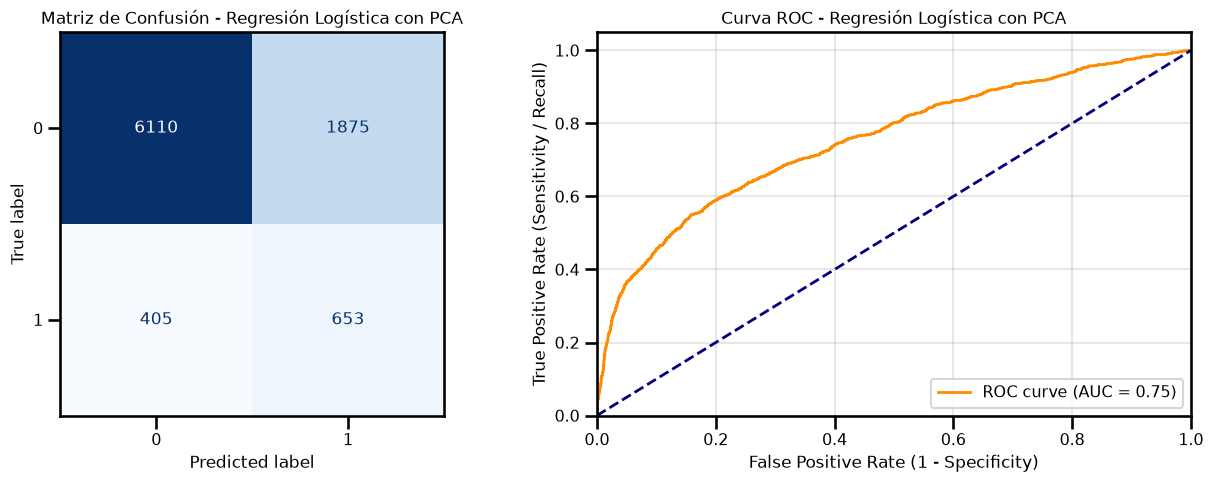

In [23]:
# Pipeline: escalado -> PCA -> Regresión Logística (misma grilla que sin PCA)
pipe_lr_pca = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA()),
    ('modelo', LogisticRegression(solver='liblinear', class_weight='balanced', max_iter=1000, random_state=42))
])

clf_lr_pca = GridSearchCV(pipe_lr_pca, param_grid=grilla_con_pca(param_lr), cv=5, scoring='roc_auc', n_jobs=-1)
clf_lr_pca.fit(xtrain_scal, ytrain)

print("Mejores hiperparámetros encontrados:", clf_lr_pca.best_params_)
print(f"Mejor AUC-ROC en Cross-Validation (Train): {clf_lr_pca.best_score_:.4f}\n")

auc_lr_pca = evaluar_en_test(clf_lr_pca, "Regresión Logística con PCA")

**KNN con PCA**

Mejores hiperparámetros encontrados: {'modelo__n_neighbors': 200, 'modelo__weights': 'distance', 'pca__n_components': 30}
Mejor AUC-ROC en Cross-Validation (Train): 0.7516

Accuracy en Test: 0.8924
AUC-ROC en Test:  0.7632

                 precision    recall  f1-score   support

No suscribe (0)      0.898     0.990     0.942      7985
   Suscribe (1)      0.676     0.154     0.251      1058

       accuracy                          0.892      9043
      macro avg      0.787     0.572     0.597      9043
   weighted avg      0.872     0.892     0.861      9043



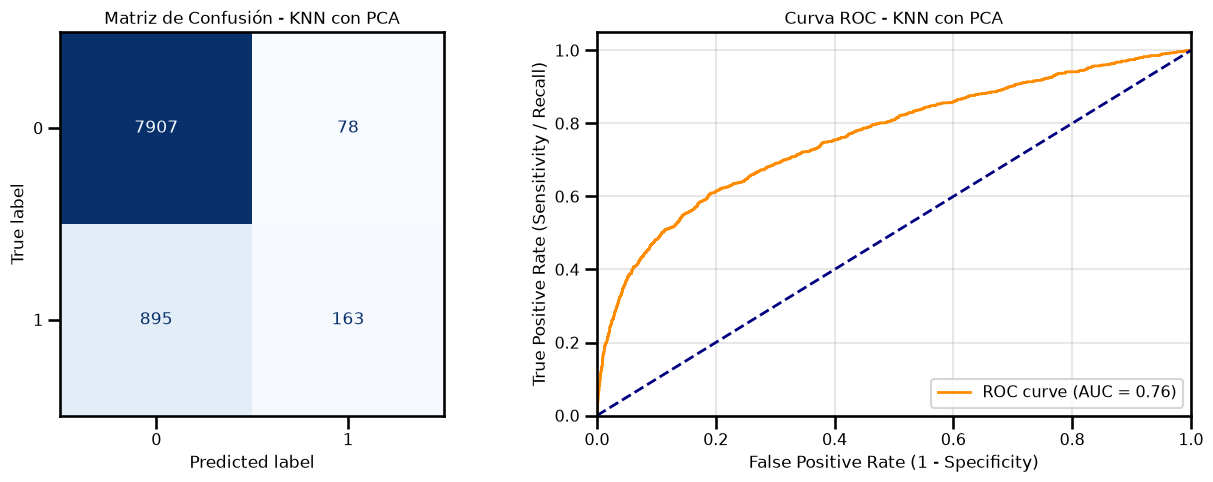

In [24]:
# Pipeline: escalado -> PCA -> KNN (misma grilla que sin PCA)
pipe_knn_pca = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA()),
    ('modelo', KNeighborsClassifier())
])

clf_knn_pca = GridSearchCV(pipe_knn_pca, param_grid=grilla_con_pca(param_knn), cv=5, scoring='roc_auc', n_jobs=-2)
clf_knn_pca.fit(xtrain_scal, ytrain)

print("Mejores hiperparámetros encontrados:", clf_knn_pca.best_params_)
print(f"Mejor AUC-ROC en Cross-Validation (Train): {clf_knn_pca.best_score_:.4f}\n")

auc_knn_pca = evaluar_en_test(clf_knn_pca, "KNN con PCA")

**Árbol de decisión con PCA**

Mejores hiperparámetros encontrados: {'modelo__criterion': 'gini', 'modelo__max_depth': 5, 'modelo__min_samples_leaf': 6, 'pca__n_components': 30}
Mejor AUC-ROC en Cross-Validation (Train): 0.7358

Accuracy en Test: 0.7131
AUC-ROC en Test:  0.7431

                 precision    recall  f1-score   support

No suscribe (0)      0.940     0.721     0.816      7985
   Suscribe (1)      0.236     0.650     0.347      1058

       accuracy                          0.713      9043
      macro avg      0.588     0.686     0.581      9043
   weighted avg      0.857     0.713     0.761      9043



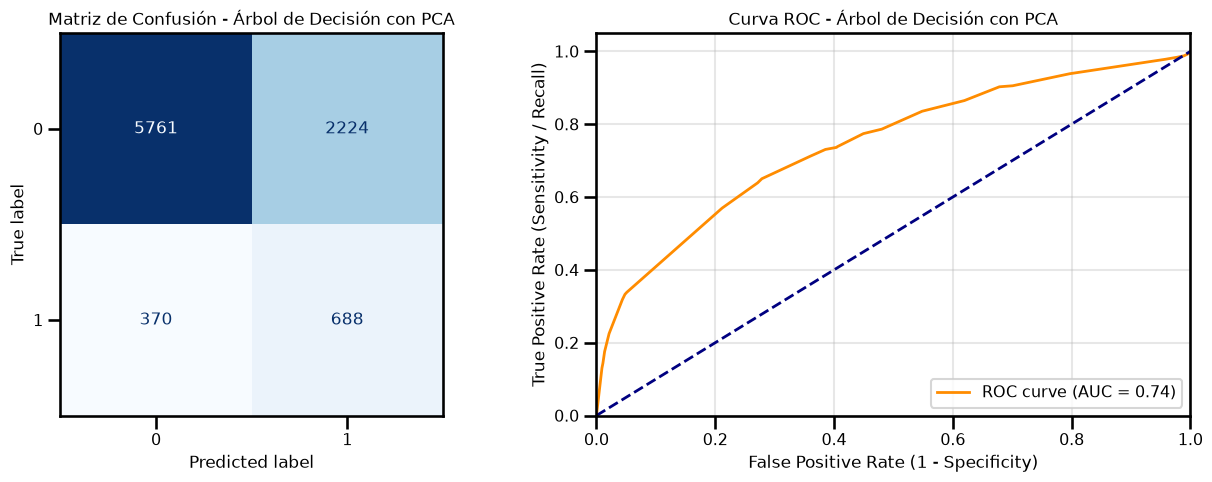

In [25]:
# Pipeline: escalado -> PCA -> Árbol de Decisión (misma grilla que sin PCA)
pipe_tree_pca = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA()),
    ('modelo', DecisionTreeClassifier(class_weight='balanced', random_state=42))
])

clf_tree_pca = GridSearchCV(pipe_tree_pca, param_grid=grilla_con_pca(param_tree), cv=5, scoring='roc_auc', n_jobs=-2)
clf_tree_pca.fit(xtrain_scal, ytrain)

print("Mejores hiperparámetros encontrados:", clf_tree_pca.best_params_)
print(f"Mejor AUC-ROC en Cross-Validation (Train): {clf_tree_pca.best_score_:.4f}\n")

auc_tree_pca = evaluar_en_test(clf_tree_pca, "Árbol de Decisión con PCA")

**Random Forest con PCA**

Mejores hiperparámetros encontrados: {'modelo__criterion': 'gini', 'modelo__max_depth': 10, 'modelo__min_samples_leaf': 6, 'modelo__n_estimators': 200, 'pca__n_components': 30}
Mejor AUC-ROC en Cross-Validation (Train): 0.7685

Accuracy en Test: 0.7956
AUC-ROC en Test:  0.7784

                 precision    recall  f1-score   support

No suscribe (0)      0.939     0.822     0.877      7985
   Suscribe (1)      0.308     0.600     0.407      1058

       accuracy                          0.796      9043
      macro avg      0.624     0.711     0.642      9043
   weighted avg      0.866     0.796     0.822      9043



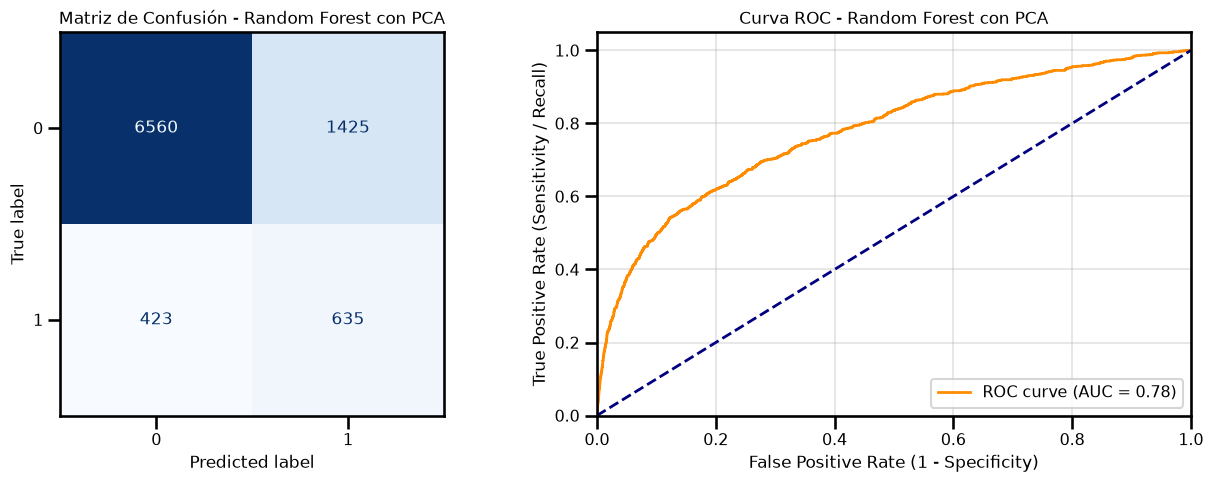

In [26]:
# Pipeline: escalado -> PCA -> Random Forest (misma grilla que sin PCA)
# Es la búsqueda más lenta: 36 combinaciones x 2 cantidades de componentes x 5 folds = 360 entrenamientos
pipe_rf_pca = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA()),
    ('modelo', RandomForestClassifier(class_weight='balanced', random_state=42))
])

clf_rf_pca = GridSearchCV(pipe_rf_pca, param_grid=grilla_con_pca(param_rf), cv=5, scoring='roc_auc', n_jobs=-2)
clf_rf_pca.fit(xtrain_scal, ytrain)

print("Mejores hiperparámetros encontrados:", clf_rf_pca.best_params_)
print(f"Mejor AUC-ROC en Cross-Validation (Train): {clf_rf_pca.best_score_:.4f}\n")

auc_rf_pca = evaluar_en_test(clf_rf_pca, "Random Forest con PCA")

### Comparación de los modelos con y sin PCA

Comparamos el AUC de validación cruzada (criterio de selección) y el de test de cada modelo entrenado con las variables originales y con las componentes principales.

In [27]:
# Tabla comparativa: mismos modelos, con y sin PCA
modelos_sin_pca = [clf_lr, clf_knn, clf_tree, clf_rf]
modelos_con_pca = [clf_lr_pca, clf_knn_pca, clf_tree_pca, clf_rf_pca]

comparacion_pca = pd.DataFrame({
    'Modelo': ['Regresión logística', 'KNN', 'Árbol de decisión', 'Random Forest'],
    'Componentes': [m.best_params_['pca__n_components'] for m in modelos_con_pca],
    'AUC CV sin PCA': [m.best_score_ for m in modelos_sin_pca],
    'AUC CV con PCA': [m.best_score_ for m in modelos_con_pca],
    'AUC test sin PCA': [auc_lr, auc_knn, auc_tree, auc_rf1],
    'AUC test con PCA': [auc_lr_pca, auc_knn_pca, auc_tree_pca, auc_rf_pca],
})
comparacion_pca['Diferencia CV'] = comparacion_pca['AUC CV con PCA'] - comparacion_pca['AUC CV sin PCA']
comparacion_pca.set_index('Modelo').round(3)

,Componentes,AUC CV sin PCA,AUC CV con PCA,AUC test sin PCA,AUC test con PCA,Diferencia CV
Modelo,,,,,,
Regresión logística,30,0.764,0.744,0.772,0.754,-0.020
KNN,30,0.761,0.752,0.772,0.763,-0.010
Árbol de decisión,30,0.739,0.736,0.759,0.743,-0.003
Random Forest,30,0.792,0.768,0.801,0.778,-0.023


### Resumen: modelos con y sin PCA

| Modelo | Variables | AUC CV | AUC test | Precision (1) | Recall (1) | F1 (1) | Llamadas (% test) |
|---|---|---|---|---|---|---|---|
| Regresión logística | 42 originales | 0,764 | 0,772 | 0,273 | 0,638 | 0,382 | 27,4% |
| Regresión logística + PCA | 30 componentes | 0,744 | 0,754 | 0,258 | 0,617 | 0,364 | 28,0% |
| KNN | 42 originales | 0,761 | 0,772 | 0,833 | 0,024 | 0,046 | 0,3% |
| KNN + PCA | 30 componentes | 0,752 | 0,763 | 0,676 | 0,154 | 0,251 | 2,7% |
| Árbol de decisión | 42 originales | 0,739 | 0,759 | 0,353 | 0,556 | 0,432 | 18,4% |
| Árbol de decisión + PCA | 30 componentes | 0,736 | 0,743 | 0,236 | 0,650 | 0,347 | 32,2% |
| **Random Forest** | 42 originales | **0,792** | **0,801** | 0,368 | 0,612 | **0,459** | 19,5% |
| Random Forest + PCA | 30 componentes | 0,768 | 0,778 | 0,308 | 0,600 | 0,407 | 22,8% |

*Precision, recall y F1 corresponden a la clase `Suscribe (1)` con threshold 0,5.*

### Conclusión: modelos con PCA

1. **PCA empeora el desempeño de los cuatro modelos.** Con las componentes principales, el AUC cae tanto en validación cruzada (entre 0,003 y 0,023) como en test (entre 0,009 y 0,023). En el árbol de decisión la diferencia en validación cruzada es mínima (0,739 contra 0,736), pero en test la caída es de 0,016. El Random Forest con las 42 variables originales sigue siendo el mejor modelo (AUC de 0,792 en validación cruzada y 0,801 en test), y su versión con PCA pierde unos 0,02 en ambos.
2. **Todos los modelos eligieron 30 componentes, el máximo de la grilla.** Cuanta más información conservan, mejor predicen. Esto confirma lo que mostró el análisis de varianza: la variabilidad está muy repartida entre las componentes y no hay un subconjunto chico que la concentre. Con 30 componentes se descarta el 9% de la variabilidad, y esa parte descartada contiene información útil para predecir la suscripción.
3. **PCA no usa la variable objetivo.** Las componentes son las direcciones de mayor variabilidad de los datos, no las que mejor separan a los clientes que suscriben de los que no, como ya se vio en el gráfico de PC1 contra PC2. Una dirección con poca varianza puede ser muy relevante para el target. El caso de la regresión logística lo muestra: es un modelo lineal y las componentes son combinaciones lineales de las variables originales, por lo que no le aportan información nueva. Solo pueden quitarle la que estaba en las 12 direcciones descartadas, y su AUC cae 0,020 en validación cruzada.
4. **Los modelos basados en árboles pierden sus cortes más informativos.** Un árbol divide los datos con una variable por vez. Sin PCA, el primer corte es `Poutcome_success`, la variable más asociada a la suscripción según el EDA. Cada componente mezcla todas las variables originales, y esa señal queda diluida. Esto explica la caída del Random Forest y el peor perfil del árbol con PCA: queda con profundidad 5 (el mínimo de la grilla) y, con threshold 0,5, llama al 32,2% de los clientes con una precision de 23,6%.
5. **El cambio en el KNN es un efecto del threshold, no una mejora.** Con PCA su recall con threshold 0,5 sube del 2,4% al 15,4%, pero su AUC baja de 0,761 a 0,752 en validación cruzada. Al cambiar las distancias entre clientes, cambian las probabilidades y más clientes superan el 0,5, pero el modelo ordena peor a los clientes.
6. **La reducción no compensa lo que se pierde.** Con 42 variables y unos 36.000 clientes, el costo computacional no es una restricción que justifique reducir la dimensionalidad. Además, las componentes no tienen una interpretación directa para el negocio, mientras que las variables originales sí.

En consecuencia, **descartamos el uso de PCA y mantenemos el Random Forest entrenado con las variables originales como modelo final.** El siguiente paso es ajustar su threshold según el supuesto de costos, usando validación cruzada sobre train, y evaluar el resultado final en test.

## Ajuste del threshold del Random Forest

El Random Forest sin PCA es el modelo elegido. Hasta ahora lo evaluamos con el threshold por defecto de 0,5, que no es adecuado para un target desbalanceado. En esta sección buscamos el threshold que mejor se ajusta a nuestro supuesto de costos.

**Por qué no maximizamos solo el recall.** Al bajar el threshold, el modelo marca más clientes como "suscribe", y el recall solo puede subir. Con un threshold de 0 se llama a todos los clientes y el recall es 1, pero esa estrategia no necesita un modelo. Por eso buscamos el threshold que mejor equilibra el recall con la precision, dándole más peso al recall.

**Criterio: F2-score.** Es una generalización del F1, en la que el parámetro β indica cuántas veces más importa el recall que la precision:

$$F_\beta = (1 + \beta^2) \cdot \frac{\text{Precision} \cdot \text{Recall}}{\beta^2 \cdot \text{Precision} + \text{Recall}}$$

Con β = 1 se obtiene el F1, que trata igual a ambos errores. Con β = 2, el recall pesa el doble que la precision, lo que refleja el supuesto de que perder una suscripción (falso negativo) es más costoso que hacer una llamada sin resultado (falso positivo).

**Sin usar test.** El threshold se elige con probabilidades *out-of-fold* sobre train: con `cross_val_predict` (5 folds), cada cliente de train recibe la probabilidad que le asigna un modelo entrenado sin él. Así, el conjunto de test se usa una única vez, para evaluar el resultado final.

In [28]:
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import precision_score, recall_score, fbeta_score

# Random Forest con los mejores hiperparámetros encontrados por GridSearchCV
rf_final = clf_rf.best_estimator_

# Probabilidades out-of-fold sobre train: cada cliente recibe la probabilidad de un modelo que no lo vio
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
yproba_oof = cross_val_predict(rf_final, xtrain_scal, ytrain, cv=cv5, method='predict_proba', n_jobs=-2)[:, 1]

fpr_oof, tpr_oof, _ = roc_curve(ytrain, yproba_oof)
print(f"AUC-ROC out-of-fold en train: {auc(fpr_oof, tpr_oof):.4f}")

AUC-ROC out-of-fold en train: 0.7907


In [29]:
# Métricas de la clase Suscribe (1) para distintos thresholds, sobre train (out-of-fold)
def metricas_threshold(y_true, y_proba, t, beta=2):
    y_pred = (y_proba >= t).astype(int)
    return {
        'Threshold': t,
        'Precision (1)': precision_score(y_true, y_pred, zero_division=0),
        'Recall (1)': recall_score(y_true, y_pred),
        'F1 (1)': fbeta_score(y_true, y_pred, beta=1, zero_division=0),
        'F2 (1)': fbeta_score(y_true, y_pred, beta=beta, zero_division=0),
        'Llamadas (%)': y_pred.mean() * 100,
    }

# Búsqueda fina del threshold que maximiza F2
grilla_t = np.round(np.arange(0.05, 0.96, 0.01), 2)
curva = pd.DataFrame([metricas_threshold(ytrain, yproba_oof, t) for t in grilla_t])
threshold_opt = curva.loc[curva['F2 (1)'].idxmax(), 'Threshold']
print(f"Threshold que maximiza F2 (train, out-of-fold): {threshold_opt:.2f}\n")

# Tabla resumida cada 0,05 para comparar
curva[np.isclose(curva['Threshold'] * 100 % 5, 0) | (curva['Threshold'] == threshold_opt)].set_index('Threshold').round(3)

Threshold que maximiza F2 (train, out-of-fold): 0.44



,Precision (1),Recall (1),F1 (1),F2 (1),Llamadas (%)
Threshold,,,,,
0.05,0.117,1.000,0.209,0.398,99.994
0.10,0.118,0.998,0.211,0.401,98.936
0.15,0.123,0.987,0.218,0.410,94.075
0.20,0.131,0.965,0.231,0.425,85.866
0.25,0.145,0.930,0.252,0.447,74.765
0.30,0.166,0.882,0.279,0.473,62.259
0.35,0.195,0.816,0.315,0.499,48.858
0.40,0.238,0.743,0.361,0.522,36.433
0.44,0.284,0.681,0.400,0.532,28.083


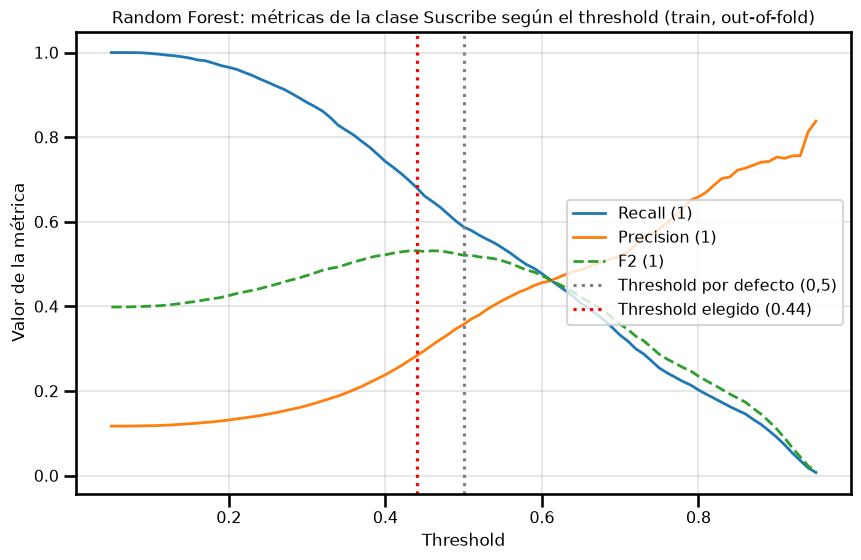

In [30]:
# Precision, recall y F2 en función del threshold (train, out-of-fold)
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(curva['Threshold'], curva['Recall (1)'], label='Recall (1)', lw=2)
ax.plot(curva['Threshold'], curva['Precision (1)'], label='Precision (1)', lw=2)
ax.plot(curva['Threshold'], curva['F2 (1)'], label='F2 (1)', lw=2, linestyle='--')
ax.axvline(0.5, color='gray', linestyle=':', label='Threshold por defecto (0,5)')
ax.axvline(threshold_opt, color='red', linestyle=':', label=f'Threshold elegido ({threshold_opt:.2f})')
ax.set_xlabel('Threshold')
ax.set_ylabel('Valor de la métrica')
ax.set_title('Random Forest: métricas de la clase Suscribe según el threshold (train, out-of-fold)')
ax.legend(loc='center right')
ax.grid(alpha=0.3)
plt.show()

Threshold elegido: 0.44

                 precision    recall  f1-score   support

No suscribe (0)      0.950     0.766     0.848      7985
   Suscribe (1)      0.283     0.696     0.402      1058

       accuracy                          0.758      9043
      macro avg      0.616     0.731     0.625      9043
   weighted avg      0.872     0.758     0.796      9043



,Precision (1),Recall (1),F1 (1),F2 (1),Llamadas (%),Suscriptores detectados,Llamadas
Threshold,,,,,,,
0.50,0.368,0.612,0.459,0.540,19.452,647,1759
0.44,0.283,0.696,0.402,0.538,28.807,736,2605


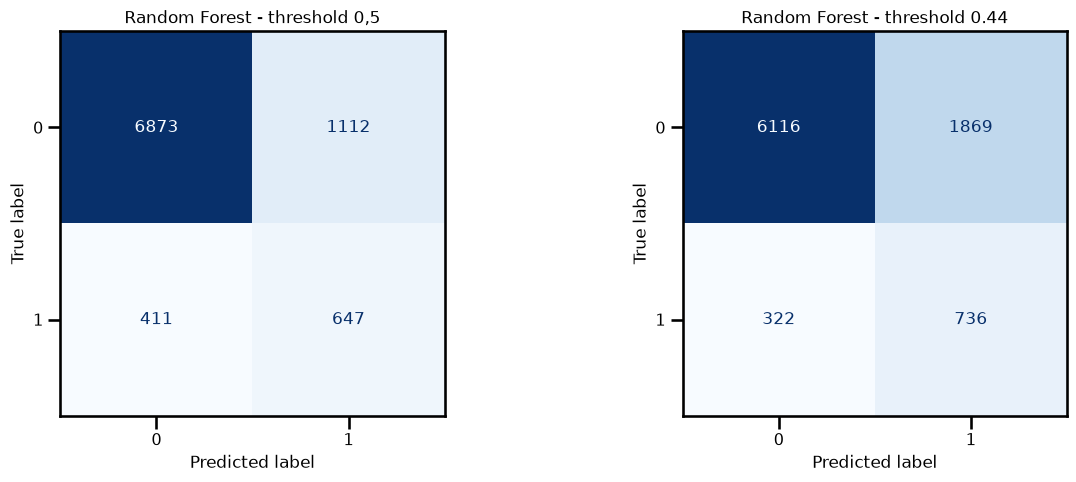

In [32]:
# Evaluación final en test con el threshold elegido (el test se usa una sola vez)
from IPython.display import display

yproba_test_rf = yproba_rf1[:, 1]
ypred_rf_05 = (yproba_test_rf >= 0.5).astype(int)
ypred_rf_opt = (yproba_test_rf >= threshold_opt).astype(int)

print(f"Threshold elegido: {threshold_opt:.2f}\n")
print(classification_report(ytest, ypred_rf_opt, target_names=clases, digits=3))

resumen_t = pd.DataFrame([metricas_threshold(ytest, yproba_test_rf, 0.5),
                          metricas_threshold(ytest, yproba_test_rf, threshold_opt)]).set_index('Threshold')
resumen_t['Suscriptores detectados'] = [ypred_rf_05[ytest.values == 1].sum(), ypred_rf_opt[ytest.values == 1].sum()]
resumen_t['Llamadas'] = [ypred_rf_05.sum(), ypred_rf_opt.sum()]
display(resumen_t.round(3))

# Matrices de confusión en test: threshold 0,5 vs. threshold elegido
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for i, (pred, titulo) in enumerate([(ypred_rf_05, 'threshold 0,5'), (ypred_rf_opt, f'threshold {threshold_opt:.2f}')]):
    ConfusionMatrixDisplay(confusion_matrix(ytest, pred), display_labels=clf_rf.classes_).plot(ax=ax[i], cmap='Blues', colorbar=False)
    ax[i].set_title('Random Forest - ' + titulo)
plt.tight_layout()
plt.show()

Conclusión: ajuste del threshold

- Threshold elegido: 0,44. Es el que maximiza el F2 sobre las probabilidades out-of-fold de train. La curva de F2 es bastante plana entre 0,40 y 0,50 (de 0,521 a 0,532), por lo que cualquier valor en ese rango daría un resultado similar.
- El resultado en test es consistente con train. Con 0,44, en train (out-of-fold) el modelo obtiene un recall de 68,1% y una precision de 28,4% llamando al 28,1% de los clientes. En test, los valores son 69,6%, 28,3% y 28,8%. El threshold no quedó sobreajustado a los datos con los que se eligió.
- Frente al threshold de 0,5: el recall sube de 61,2% a 69,6%: el modelo detecta 736 de los 1.058 suscriptores en lugar de 647, y los suscriptores sin llamar bajan de 411 a 322. A cambio, las llamadas aumentan de 1.759 a 2.605 (del 19,5% al 28,8% de los clientes) y la precision baja de 36,8% a 28,3%.
- El costo de esas suscripciones adicionales: las 846 llamadas extra consiguen 89 suscripciones más, una tasa de 10,5%, similar a la tasa base de 11,7%. Bajar el threshold conviene si una suscripción vale más que unas 10 llamadas, que es justamente lo que asume nuestro supuesto de costos. Si el banco considerara que las llamadas son caras, el threshold de 0,5 o uno mayor sería preferible.
- En términos del negocio: llamando a menos de 3 de cada 10 clientes, el banco alcanza a casi el 70% de los suscriptores, unas 2,4 veces lo que lograría llamando a la misma cantidad de clientes al azar.